In [ ]:

import pandas as pd

url = "https://storage.data.gov.my/agriculture/crops_district_production.csv"

df = pd.read_csv(url)

df['date'] = pd.to_datetime(df['date'])

df['year'] = df['date'].dt.year

popped_column = df.pop('date')

dfresult = df.dropna()

print(dfresult)

             state     district   crop_type   crop_species  production  year
0            Johor   Batu Pahat  cash_crops        cassava   920.50000  2017
1            Johor   Batu Pahat  cash_crops     groundnuts     0.00000  2017
2            Johor   Batu Pahat  cash_crops     sweet_corn     0.00000  2017
3            Johor   Batu Pahat  cash_crops   sweet_potato   350.00000  2017
4            Johor   Batu Pahat  cash_crops            yam   395.40000  2017
...            ...          ...         ...            ...         ...   ...
10997  W.P. Labuan  W.P. Labuan   vegetable        mustard   143.94500  2017
10998  W.P. Labuan  W.P. Labuan   vegetable     red_chilli     3.40100  2017
10999  W.P. Labuan  W.P. Labuan   vegetable   spring_onion     3.11590  2017
11000  W.P. Labuan  W.P. Labuan   vegetable    sweet_shoot     9.70295  2017
11001  W.P. Labuan  W.P. Labuan   vegetable  water_spinach    63.91800  2017

[11002 rows x 6 columns]


In [ ]:
url2 = "https://storage.dosm.gov.my/gdp/gdp_district_real_supply.csv"

df2 = pd.read_csv(url2)
df2['date'] = pd.to_datetime(df2['date'])

df2['year'] = df2['date'].dt.year

popped_column = df2.pop('date')

year_2017 = df2[df2['year'] == 2017]
growth = year_2017[year_2017["series"] == "growth_yoy"]
agriculture = growth[growth["sector"] == "p1"]
print(agriculture)




           series              state           district sector  value  year
5803   growth_yoy              Johor         Batu Pahat     p1    4.8  2017
5833   growth_yoy              Johor        Johor Bahru     p1    9.9  2017
5863   growth_yoy              Johor             Kluang     p1    7.4  2017
5893   growth_yoy              Johor        Kota Tinggi     p1    8.9  2017
5923   growth_yoy              Johor              Kulai     p1    9.8  2017
...           ...                ...                ...    ...    ...   ...
10483  growth_yoy         Terengganu   Kuala Terengganu     p1   19.3  2017
10513  growth_yoy         Terengganu             Marang     p1    9.9  2017
10543  growth_yoy         Terengganu              Setiu     p1   15.3  2017
10573  growth_yoy  W.P. Kuala Lumpur  W.P. Kuala Lumpur     p1    NaN  2017
10603  growth_yoy        W.P. Labuan        W.P. Labuan     p1    3.7  2017

[161 rows x 6 columns]


In [ ]:
dfresult2 = agriculture.dropna()
df_final = pd.merge(dfresult, dfresult2[['district', 'value']], on = 'district', how = 'inner')
print(df_final)


             state     district   crop_type   crop_species  production  year  \
0            Johor   Batu Pahat  cash_crops        cassava   920.50000  2017   
1            Johor   Batu Pahat  cash_crops     groundnuts     0.00000  2017   
2            Johor   Batu Pahat  cash_crops     sweet_corn     0.00000  2017   
3            Johor   Batu Pahat  cash_crops   sweet_potato   350.00000  2017   
4            Johor   Batu Pahat  cash_crops            yam   395.40000  2017   
...            ...          ...         ...            ...         ...   ...   
10930  W.P. Labuan  W.P. Labuan   vegetable        mustard   143.94500  2017   
10931  W.P. Labuan  W.P. Labuan   vegetable     red_chilli     3.40100  2017   
10932  W.P. Labuan  W.P. Labuan   vegetable   spring_onion     3.11590  2017   
10933  W.P. Labuan  W.P. Labuan   vegetable    sweet_shoot     9.70295  2017   
10934  W.P. Labuan  W.P. Labuan   vegetable  water_spinach    63.91800  2017   

       value  
0        4.8  
1        

**Linear Regression**

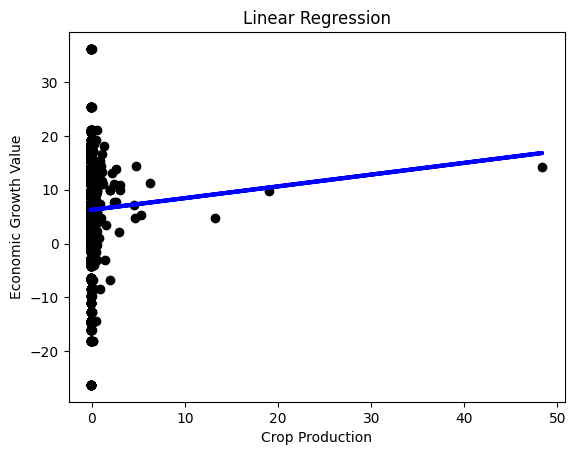

0.0005927347023103602
Mean Squared Error: 70.66316563912845
R-squared: 9.18848960280716e-05


In [ ]:
!pip install scikit-learn
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()


X = df_final[['production']]
Y = df_final['value']
x_scaled = scaler.fit_transform(X)

X_train, X_test, Y_train, Y_test = train_test_split(x_scaled, Y, test_size=0.2, random_state=42)

reg = LinearRegression()
reg.fit(X_train, Y_train)
y_pred = reg.predict(X_test)

mse = mean_squared_error(Y_test, y_pred)
r2 = r2_score(Y_test, y_pred)

plt.scatter(X_test, Y_test, color='black')
plt.plot(X_test, y_pred, color='blue', linewidth=3)
plt.xlabel('Crop Production')
plt.ylabel('Economic Growth Value')
plt.title('Linear Regression')
plt.show()

print(reg.score(x_scaled, Y))
print("Mean Squared Error:", mse)
print("R-squared:", r2)


**SUPPORT VECTOR REGRESSOR**

========== SVR Model Evaluation ==========
Best SVR Parameters: {'C': 100, 'epsilon': 0.5, 'kernel': 'rbf'}
Mean Squared Error (MSE): 35.82527161448884
Root Mean Squared Error (RMSE): 5.985421590371796
R-squared (R²): 0.03338997773629171

Sample Predictions:
      Actual 2018 Value  Predicted 2018 Value
533                -1.2              2.429948
3139                0.5             -1.300796
932                -4.2             -0.336861
5924               -3.9             -0.315861
9498                2.6              3.553358


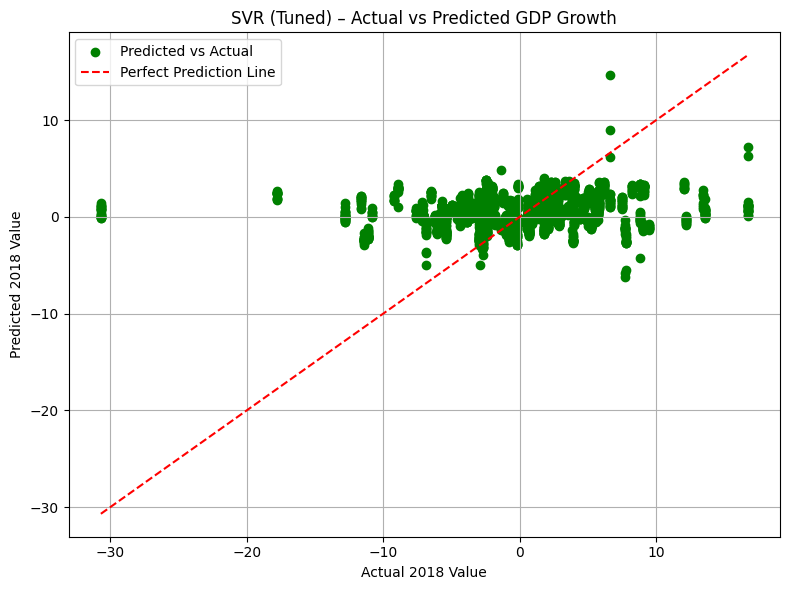

In [ ]:
# === Imports ===
import pandas as pd
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import SVR
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.metrics import r2_score, mean_squared_error
import matplotlib.pyplot as plt

# === Load 2017 Data ===
df_train = df_final.copy()  # Assumes df_final is already loaded with 2017 data
df_train = df_train.rename(columns={'year': 'year_2017'})

# === Load 2018 Label Data ===
url2 = "https://storage.dosm.gov.my/gdp/gdp_district_real_supply.csv"
df2 = pd.read_csv(url2)
df2['date'] = pd.to_datetime(df2['date'])
df2['year'] = df2['date'].dt.year
df_label_2018 = df2[
    (df2['year'] == 2018) &
    (df2['series'] == 'growth_yoy') &
    (df2['sector'] == 'p1')
][['district', 'value']].dropna()

# === Merge for Training Data ===
df_train_full = pd.merge(df_train, df_label_2018, on='district', suffixes=('_2017', '_2018'))

# === Encode Categorical Columns ===
label_encoders = {}
for col in ['state', 'district', 'crop_type', 'crop_species']:
    le = LabelEncoder()
    df_train_full[col] = le.fit_transform(df_train_full[col])
    label_encoders[col] = le

# === Define Features and Target ===
feature_cols = ['state', 'district', 'crop_type', 'crop_species', 'production', 'year_2017']
X = df_train_full[feature_cols]
y = df_train_full['value_2018']

# === Train/Test Split ===
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# === Feature Scaling ===
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# === Hyperparameter Tuning ===
param_grid = {
    'C': [0.1, 1, 10, 100],
    'epsilon': [0.01, 0.1, 0.5],
    'kernel': ['rbf']
}
grid_search = GridSearchCV(SVR(), param_grid, cv=5, scoring='neg_mean_squared_error')
grid_search.fit(X_train_scaled, y_train)

# === Best SVR Model ===
best_svr = grid_search.best_estimator_

# === Prediction and Evaluation ===
y_pred = best_svr.predict(X_test_scaled)
mse = mean_squared_error(y_test, y_pred)
rmse = mse ** 0.5
r2 = r2_score(y_test, y_pred)

# === Display Results ===
print("========== SVR Model Evaluation ==========")
print("Best SVR Parameters:", grid_search.best_params_)
print("Mean Squared Error (MSE):", mse)
print("Root Mean Squared Error (RMSE):", rmse)
print("R-squared (R²):", r2)

# === Actual vs Predicted DataFrame ===
results_df = pd.DataFrame({'Actual 2018 Value': y_test, 'Predicted 2018 Value': y_pred})
print("\nSample Predictions:")
print(results_df.head())

# === Plot Actual vs Predicted ===
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, color='green', label='Predicted vs Actual')
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], 'r--', label='Perfect Prediction Line')
plt.xlabel('Actual 2018 Value')
plt.ylabel('Predicted 2018 Value')
plt.title('SVR (Tuned) – Actual vs Predicted GDP Growth')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()




**BAYESIAN RIDGE REGRESSION**


R2 Score: 0.00047061007861004533
Mean Squared Error: 37.045355475146266


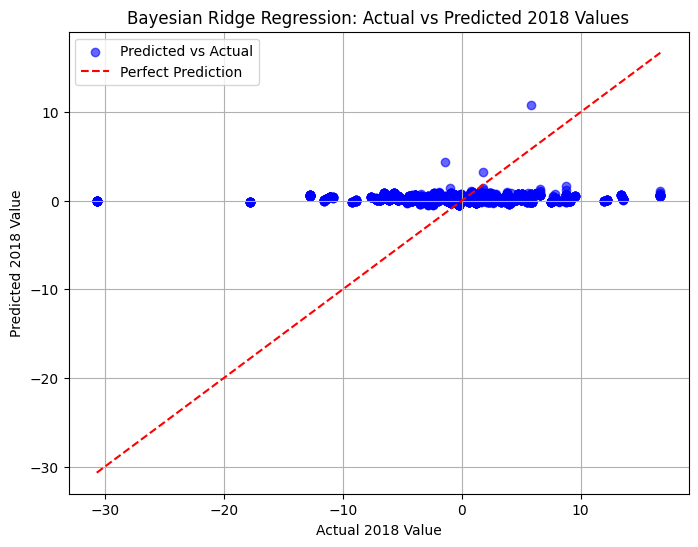

In [ ]:

import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import BayesianRidge
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
import matplotlib.pyplot as plt

df_train = df_final.copy()

df_train = df_train.rename(columns={'year': 'year_2017'})

url2 = "https://storage.dosm.gov.my/gdp/gdp_district_real_supply.csv"
df2 = pd.read_csv(url2)
df2['date'] = pd.to_datetime(df2['date'])
df2['year'] = df2['date'].dt.year

year_2018 = df2[df2['year'] == 2018]
growth_2018 = year_2018[year_2018["series"] == "growth_yoy"]
agriculture_2018 = growth_2018[growth_2018["sector"] == "p1"]

df_label_2018 = agriculture_2018.dropna()[['district', 'value']]

df_train_full = pd.merge(df_train, df_label_2018, on='district', suffixes=('_2017', '_2018'))

label_encoders = {}
categorical_cols = ['state', 'district', 'crop_type', 'crop_species']

for col in categorical_cols:
    le = LabelEncoder()
    le.fit(df_train_full[col])
    df_train_full[col] = le.transform(df_train_full[col])
    label_encoders[col] = le

feature_cols = ['state', 'district', 'crop_type', 'crop_species', 'production', 'year_2017']
X = df_train_full[feature_cols]
y = df_train_full['value_2018']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = BayesianRidge()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("R2 Score:", r2_score(y_test, y_pred))
print("Mean Squared Error:", mean_squared_error(y_test, y_pred))

plt.figure(figsize=(8,6))
plt.scatter(y_test, y_pred, alpha=0.6, color='b', label='Predicted vs Actual')

min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], 'r--', label='Perfect Prediction')

plt.xlabel('Actual 2018 Value')
plt.ylabel('Predicted 2018 Value')
plt.title('Bayesian Ridge Regression: Actual vs Predicted 2018 Values')
plt.legend()
plt.grid(True)
plt.show()

**CLUSTERING**

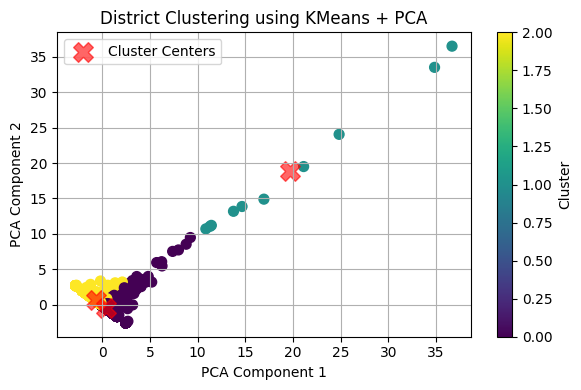


--- Clustering Evaluation ---
R² Score: 0.7468
Mean Squared Error: 0.2532

Sample of Clustering Result:
     district  cluster
0  Batu Pahat        0
1  Batu Pahat        2
2  Batu Pahat        2
3  Batu Pahat        0
4  Batu Pahat        0


In [ ]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt
import numpy as np

features = df_final.select_dtypes(include=['number'])
scaler = StandardScaler()
scaled_features = scaler.fit_transform(features)

kmeans = KMeans(n_clusters=3, random_state=42)
kmeans.fit(scaled_features)

df_final['cluster'] = kmeans.labels_

pca = PCA(n_components=2)
reduced = pca.fit_transform(scaled_features)

plt.figure(figsize=(6, 4))
scatter = plt.scatter(reduced[:, 0], reduced[:, 1], c=df_final['cluster'], cmap='viridis', s=50)
centers_2d = pca.transform(kmeans.cluster_centers_)
plt.scatter(centers_2d[:, 0], centers_2d[:, 1], c='red', s=200, alpha=0.6, label='Cluster Centers', marker='X')

plt.title('District Clustering using KMeans + PCA')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.colorbar(scatter, label='Cluster')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

reconstructed = np.array([kmeans.cluster_centers_[label] for label in kmeans.labels_])

r2 = r2_score(scaled_features, reconstructed)
mse = mean_squared_error(scaled_features, reconstructed)

print("\n--- Clustering Evaluation ---")
print(f"R² Score: {r2:.4f}")
print(f"Mean Squared Error: {mse:.4f}")

print("\nSample of Clustering Result:")
print(df_final[['district', 'cluster']].head())

Gaussian Mixture Model

Means:
 [[-0.04876294 -0.02846947]
 [ 1.29797251  0.10706681]
 [-0.09367534  0.00295914]]

Covariances:
 [[[ 2.37584276e-03  1.01130871e-03]
  [ 1.01130871e-03  8.93898301e-01]]

 [[ 1.54144318e+01  2.80519220e-01]
  [ 2.80519220e-01  6.02821201e-01]]

 [[ 1.86584725e-06 -4.36469710e-05]
  [-4.36469710e-05  1.08018857e+00]]]
             state     district   crop_type   crop_species  production  year  \
0            Johor   Batu Pahat  cash_crops        cassava   920.50000  2017   
1            Johor   Batu Pahat  cash_crops     groundnuts     0.00000  2017   
2            Johor   Batu Pahat  cash_crops     sweet_corn     0.00000  2017   
3            Johor   Batu Pahat  cash_crops   sweet_potato   350.00000  2017   
4            Johor   Batu Pahat  cash_crops            yam   395.40000  2017   
...            ...          ...         ...            ...         ...   ...   
10930  W.P. Labuan  W.P. Labuan   vegetable        mustard   143.94500  2017   
10931  W.P. Labuan  W.P. Labuan  

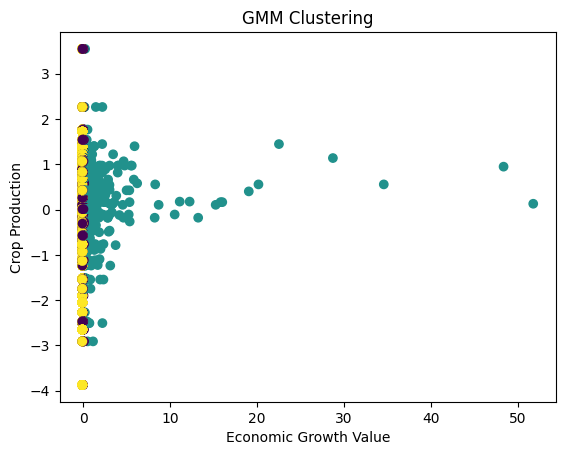


--- GMM Clustering Evaluation ---
R² Score: 0.0532
Mean Squared Error: 0.9468


In [ ]:
!pip install scikit-learn
import numpy as np
import matplotlib.pyplot as plt
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

# load data
df_gm = df_final.copy()
gm = df_gm[['production', 'value']].values

#feature scaling
scaler = StandardScaler()
gm = scaler.fit_transform(gm)

# train data
gmm = GaussianMixture(n_components = 3, random_state = 42)
gmm.fit(gm)

#predict cluster labels and probabilities
labels = gmm.predict(gm)
probs = gmm.predict_proba(gm)

#print means and covariances
print("Means:\n", gmm.means_)
print("\nCovariances:\n", gmm.covariances_)

#add the labels to the data frame
df_gm['cluster'] = labels

#print updated data frame
print(df_gm)

#visualize
plt.scatter(gm[:, 0], gm[:, 1], c = labels, cmap = 'viridis')
plt.title("GMM Clustering")
plt.xlabel("Economic Growth Value")
plt.ylabel("Crop Production")
plt.show()

predicted = gmm.means_[labels]
mse = mean_squared_error(gm, predicted)
r2 = r2_score(gm, predicted)

print("\n--- GMM Clustering Evaluation ---")
print(f"R² Score: {r2:.4f}")
print(f"Mean Squared Error: {mse:.4f}")

**Evaluation for AUTO-SKLEARN**

In [ ]:
!pip install auto-sklearn

import autosklearn.regression
import numpy as np
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

# df: your combined dataset with 2017 as input and 2018 GDP growth as target
# You’ve already cleaned NaNs, and selected relevant 2017 data
# Now, encode categorical values
# Ensure df_train_full is used as it contains both 2017 features and 2018 target
# based on previous cells
df = df_train_full.copy()

categorical_cols = ['state', 'district', 'crop_type']  # Adjust this if needed
for col in categorical_cols:
    # Use the existing label encoders if they were fitted on the full dataset
    # Otherwise, fit and transform here
    if col in label_encoders:
        df[col] = label_encoders[col].transform(df[col])
    else:
        le = LabelEncoder()
        df[col] = le.fit_transform(df[col])
        # Optional: store this new encoder
        # label_encoders[col] = le


# Define features (X) and target (y)
# Ensure the target column name 'value_2018' from the previous merge is used
X = df.drop(columns=['value_2018'])
y = df['value_2018']

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standardize
scaler = StandardScaler()
# Ensure X_train and X_test have consistent columns before scaling
# This might require selecting only the numerical features and encoded categoricals
# Based on the previous code, X includes 'state', 'district', 'crop_type',
# 'crop_species', 'production', 'year_2017'
# and y is 'value_2018'. Let's make sure X only contains the feature columns
feature_cols = ['state', 'district', 'crop_type', 'crop_species', 'production', 'year_2017']
X = df[feature_cols] # Redefine X using the correct features from the encoded df

# Split again after redefining X
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

automl = autosklearn.regression.AutoSklearnRegressor(
    time_left_for_this_task=600,         # Total search time in seconds
    per_run_time_limit=60,               # Limit per model
    tmp_folder='/tmp/autosklearn_regression',
    seed=42
)

automl.fit(X_train, y_train)
# Make predictions
y_pred = automl.predict(X_test)

# Evaluation
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("🔎 AutoSklearn Model Evaluation:")
print(f"R² Score: {r2:.4f}")
print(f"MSE: {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
# Display best pipeline/model
print("\n📌 Best Models Found:")
print(automl.show_models())

# Leaderboard of all tried models
print("\n📈 Model Leaderboard:")
print(automl.leaderboard())


plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, color='blue', label='Predictions')
# Ensure the plot line covers the range of actual and predicted values
plot_min = min(y_test.min(), y_pred.min())
plot_max = max(y_test.max(), y_pred.max())
plt.plot([plot_min, plot_max], [plot_min, plot_max], 'r--', label='Perfect Prediction')

plt.xlabel("Actual GDP Growth (2018)")
plt.ylabel("Predicted GDP Growth")
plt.title("AutoSklearn: Actual vs Predicted")
plt.legend()
plt.grid(True)
plt.show()

  Using cached auto-sklearn-0.15.0.tar.gz (6.5 MB)
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Using cached scikit-learn-0.24.2.tar.gz (7.5 MB)
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  error: subprocess-exited-with-error
  
  × Preparing metadata (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Preparing metadata (pyproject.toml) ... error
error: metadata-generation-failed

× Encountered error while generating package metadata.
╰─> See above for output.

note: This is an issue with the package mentioned above, not pip.
hint: See above for details.


ModuleNotFoundError: No module named 'autosklearn'